# Rush 2 – Analyse des ventes d'une pharmacie

Ce notebook reprend toute l'analyse étape par étape, avec les résultats affichés sous chaque cellule.

| Partie | Question |
|---|---|
| 1 | Les 4 exports du client disent-ils la même chose ? |
| 2 | Quels groupes pèsent le plus, quand se vendent-ils ? |
| 3 | Quels groupes sont saisonniers ? |
| 4 | Peut-on prévoir le mois suivant ? |
| 5 | Les ventes suivent-elles les épidémies de grippe ? |

Pour la mise à jour mensuelle, on utilise les scripts `.py` du dépôt. Ce notebook sert à **comprendre et montrer** l'analyse.
Pour l'exécuter : menu **Run All** (ou « Exécuter tout »).

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.precision", 2)

GROUPES = ["M01AB", "M01AE", "N02BA", "N02BE", "N05B", "N05C", "R03", "R06"]
NOMS = {
    "M01AB": "Diclofénac", "M01AE": "Ibuprofène", "N02BA": "Aspirine", "N02BE": "Paracétamol",
    "N05B": "Anxiolytiques", "N05C": "Somnifères", "R03": "Asthme", "R06": "Antihistaminiques",
}

## 1. Les 4 exports disent-ils la même chose ?

Chaque export a son propre format de date : format américain (mois/jour/année) pour l'horaire, le journalier et l'hebdo, format ISO (année-mois-jour) pour le mensuel.

In [2]:
horaire = pd.read_csv("data/Pharma_Ventes_Hourly.csv")
horaire["datum"] = pd.to_datetime(horaire["datum"], format="%m/%d/%Y %H:%M")

journalier = pd.read_csv("data/Pharma_Ventes_Daily.csv")
journalier["datum"] = pd.to_datetime(journalier["datum"], format="%m/%d/%Y")

hebdo = pd.read_csv("data/Pharma_Ventes_Weekly.csv")
hebdo["datum"] = pd.to_datetime(hebdo["datum"], format="%m/%d/%Y")

mensuel = pd.read_csv("data/Pharma_Ventes_Monthly.csv")
mensuel["datum"] = pd.to_datetime(mensuel["datum"], format="%Y-%m-%d")

fiches = []
for nom, df in [("Horaire", horaire), ("Journalier", journalier), ("Hebdo", hebdo), ("Mensuel", mensuel)]:
    fiches.append({
        "Export": nom, "Début": df["datum"].min().date(), "Fin": df["datum"].max().date(),
        "Lignes": len(df), "Doublons": df["datum"].duplicated().sum(),
        "Valeurs vides": df[GROUPES].isna().sum().sum(), "Valeurs négatives": (df[GROUPES] < 0).sum().sum(),
    })
pd.DataFrame(fiches).set_index("Export")

,Début,Fin,Lignes,Doublons,Valeurs vides,Valeurs négatives
Export,,,,,,
Horaire,2014-01-02,2019-10-08,50532,0,0,0
Journalier,2014-01-02,2019-10-08,2106,0,0,0
Hebdo,2014-01-05,2019-10-13,302,0,0,0
Mensuel,2014-01-31,2019-10-31,70,0,0,0


On additionne le journalier par jour, par semaine et par mois, puis on compare aux autres exports.

In [3]:
jour = journalier.set_index("datum")[GROUPES]

def comparer(reference, a_verifier):
    communs = reference.index.intersection(a_verifier.index)
    ecart = (reference.loc[communs] - a_verifier.loc[communs]).abs()
    return len(communs), int((ecart > 0.01).any(axis=1).sum()), ecart

comparaisons = {
    "Horaire additionné par jour vs Journalier": comparer(jour, horaire.set_index("datum")[GROUPES].resample("D").sum()),
    "Journalier additionné par semaine vs Hebdo": comparer(hebdo.set_index("datum")[GROUPES], jour.resample("W-SUN").sum()),
    "Journalier additionné par mois vs Mensuel": comparer(mensuel.set_index("datum")[GROUPES], jour.resample("ME").sum()),
}
pd.DataFrame(
    [(k, n, e) for k, (n, e, _) in comparaisons.items()],
    columns=["Comparaison", "Périodes comparées", "Périodes en écart"],
).set_index("Comparaison")

,Périodes comparées,Périodes en écart
Comparaison,,
Horaire additionné par jour vs Journalier,2106,0
Journalier additionné par semaine vs Hebdo,302,0
Journalier additionné par mois vs Mensuel,70,31


In [4]:
# Détail des mois où le mensuel ne colle pas (écart = mensuel - somme des jours)
_, _, ecart_mensuel = comparaisons["Journalier additionné par mois vs Mensuel"]
ecart_mensuel[(ecart_mensuel > 0.01).any(axis=1)].round(1).head(10)

,M01AB,M01AE,N02BA,N02BE,N05B,N05C,R03,R06
datum,,,,,,,,
2014-01-31,0.0,0.0,0.0,0.0,0.0,20.0,0.0,0.0
2014-04-30,0.0,0.0,5.7,0.0,0.0,0.0,0.0,0.0
2014-08-31,10.0,0.0,0.0,36.5,0.0,0.0,0.0,0.0
2014-09-30,0.0,0.0,10.0,0.0,0.0,0.0,0.0,0.0
2014-10-31,53.6,76.5,51.1,783.7,39.9,10.4,22.0,27.8
2015-03-31,0.0,0.0,0.0,0.0,0.0,0.0,25.0,0.0
2015-06-30,0.0,0.0,0.0,31.4,0.0,0.0,0.0,0.0
2015-11-30,10.0,0.0,0.0,42.8,0.0,0.0,30.0,0.0
2016-03-31,0.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0


**Conclusion :** l'horaire, le journalier et l'hebdo concordent parfaitement. Le **mensuel est faux sur 31 mois sur 70** : il est écarté.
Le **journalier** devient le fichier de référence, et les mois sont recalculés à partir des jours.
On ne garde que les **mois complets** : janvier 2014 (il manque le 1er) et octobre 2019 (8 jours) sont exclus.

In [5]:
mois = jour.resample("MS").sum()
jours_par_mois = jour.resample("MS").size()
mois = mois[jours_par_mois == jours_par_mois.index.days_in_month]
print(f"{len(mois)} mois complets, de {mois.index.min():%m/%Y} à {mois.index.max():%m/%Y}")

68 mois complets, de 02/2014 à 09/2019


## 2. Statistiques descriptives

In [6]:
synthese = pd.DataFrame({
    "Groupe": [NOMS[g] for g in GROUPES],
    "Total": mois.sum(),
    "Part du total (%)": mois.sum() / mois.sum().sum() * 100,
    "Moyenne / mois": mois.mean(),
    "Mois le plus bas": mois.min(),
    "Mois le plus haut": mois.max(),
    "Irrégularité (%)": mois.std() / mois.mean() * 100,
}).sort_values("Total", ascending=False).round(1)
synthese

,Groupe,Total,Part du total (%),Moyenne / mois,Mois le plus bas,Mois le plus haut,Irrégularité (%)
N02BE,Paracétamol,62941.4,49.6,925.6,479.4,1822.8,34.4
N05B,Anxiolytiques,18167.0,14.3,267.2,135.0,525.0,28.5
R03,Asthme,11593.1,9.1,170.5,37.0,402.0,45.7
M01AB,Diclofénac,10547.6,8.3,155.1,98.4,211.1,15.0
M01AE,Ibuprofène,8193.8,6.5,120.5,88.3,207.6,16.2
N02BA,Aspirine,8014.4,6.3,117.9,75.2,187.0,20.6
R06,Antihistaminiques,6101.2,4.8,89.7,34.6,213.0,50.1
N05C,Somnifères,1212.0,1.0,17.8,5.0,42.0,40.9


- Le **paracétamol** fait à lui seul **la moitié des ventes**.
- Les plus irréguliers (donc les plus durs à gérer en stock) : **antihistaminiques** et **asthme**, les deux groupes saisonniers.

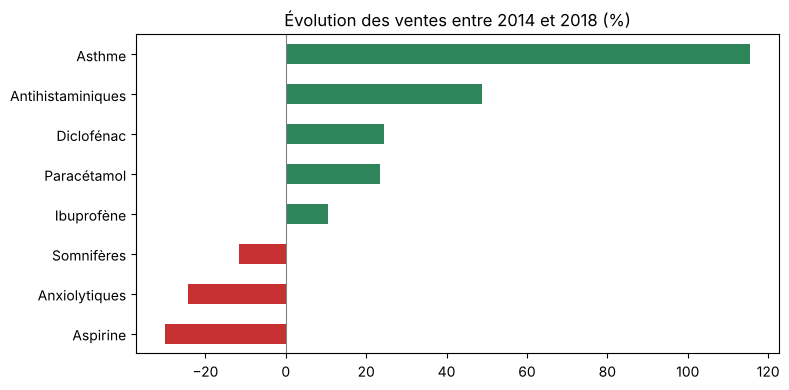

In [7]:
annees = jour.resample("YE").sum()
annees.index = annees.index.year
annees = annees.loc[2014:2018]
evolution = ((annees.loc[2018] / annees.loc[2014] - 1) * 100).rename(index=NOMS).sort_values()

evolution.plot.barh(figsize=(8, 4), color=["#c53030" if v < 0 else "#2f855a" for v in evolution])
plt.title("Évolution des ventes entre 2014 et 2018 (%)")
plt.axvline(0, color="grey", lw=0.8)
plt.tight_layout()
plt.show()

L'**asthme** a plus que doublé (+115 %) ; l'**aspirine** (−30 %) et les **anxiolytiques** (−24 %) reculent.

In [8]:
noms_jours = ["Lundi", "Mardi", "Mercredi", "Jeudi", "Vendredi", "Samedi", "Dimanche"]
par_jour = jour.groupby(jour.index.dayofweek).mean()
par_jour.index = noms_jours
par_jour.rename(columns=NOMS).round(1)

,Diclofénac,Ibuprofène,Aspirine,Paracétamol,Anxiolytiques,Somnifères,Asthme,Antihistaminiques
Lundi,5.1,3.8,3.9,30.0,9.3,0.6,6.0,2.9
Mardi,5.1,3.6,4.2,28.6,9.6,0.7,5.5,3.1
Mercredi,4.8,3.7,3.7,28.2,10.0,0.7,5.5,2.7
Jeudi,4.6,3.7,3.7,28.6,8.7,0.5,5.4,2.6
Vendredi,4.8,3.8,3.9,29.2,9.9,0.8,5.8,2.8
Samedi,5.8,4.4,4.2,34.0,8.5,0.5,5.6,3.3
Dimanche,5.4,4.7,3.5,34.6,5.7,0.3,5.2,3.1


Paracétamol et anti-inflammatoires se vendent le plus le **week-end** ; les **anxiolytiques chutent le dimanche** (médicaments sur ordonnance, médecins fermés).

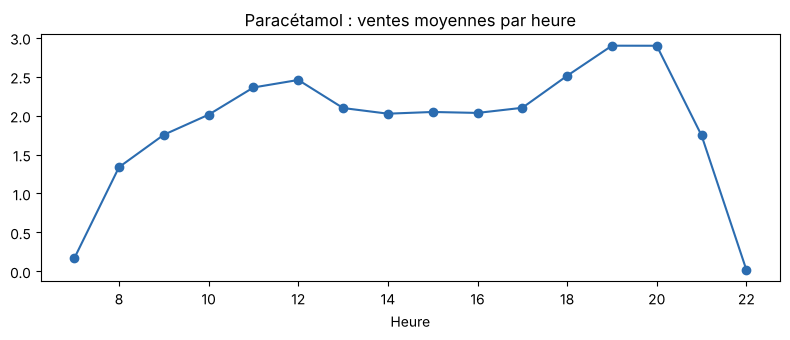

In [9]:
par_heure = horaire.groupby(horaire["datum"].dt.hour)[GROUPES].mean().loc[7:22]
(par_heure["N02BE"]).plot(figsize=(8, 3.5), marker="o", color="#2b6cb0")
plt.title("Paracétamol : ventes moyennes par heure")
plt.xlabel("Heure")
plt.tight_layout()
plt.show()

Deux pics dans la journée : **11h-12h** et **19h-20h** (après le travail). Utile pour organiser le personnel.

## 3. Saisonnalité

Indice d'un mois = ventes du mois / moyenne des mois complets du groupe. **1,40** veut dire « 40 % au-dessus d'un mois normal ».

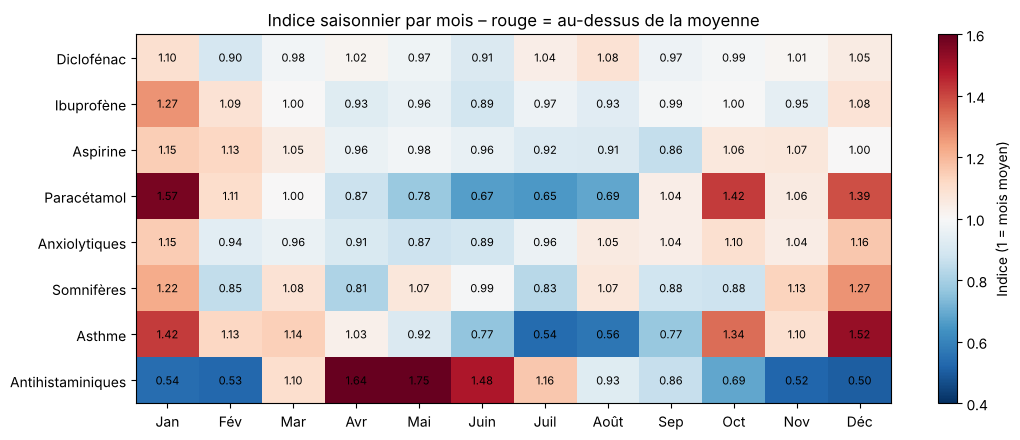

In [10]:
noms_mois = ["Jan", "Fév", "Mar", "Avr", "Mai", "Juin", "Juil", "Août", "Sep", "Oct", "Nov", "Déc"]
indice = mois.groupby(mois.index.month).mean() / mois.mean()
indice.index = noms_mois

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(indice.T.values, cmap="RdBu_r", vmin=0.4, vmax=1.6, aspect="auto")
ax.set_xticks(range(12), noms_mois)
ax.set_yticks(range(len(GROUPES)), [NOMS[g] for g in GROUPES])
for i, g in enumerate(GROUPES):
    for j in range(12):
        ax.text(j, i, f"{indice[g].iloc[j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, label="Indice (1 = mois moyen)")
ax.set_title("Indice saisonnier par mois – rouge = au-dessus de la moyenne")
plt.tight_layout()
plt.show()

- **Antihistaminiques** : pic d'avril à juin (saison des pollens), creux en hiver.
- **Paracétamol et asthme** : forts d'octobre à janvier, au plus bas en juillet-août.
- **Diclofénac, anxiolytiques** : quasi pas de saison.

## 4. Peut-on prévoir le mois suivant ?

**Le test :** on se replace chaque mois de janvier 2018 à septembre 2019 (21 mois), on prévoit le mois suivant avec uniquement ce qu'on savait à ce moment-là, puis on compare au réel.

On compare 2 prévisions **naïves** (ce que n'importe qui ferait) à 2 méthodes **à nous**. Un groupe est jugé prévisible si notre meilleure méthode fait **au moins 2 points d'erreur de moins** que la meilleure naïve.

In [11]:
def naive_mois_dernier(historique, mois_cible):
    return historique.iloc[-1]

def naive_annee_derniere(historique, mois_cible):
    return historique.loc[mois_cible - pd.DateOffset(years=1)]

def moyenne_3_mois(historique, mois_cible):
    return historique.iloc[-3:].mean()

def saison_et_niveau(historique, mois_cible):
    niveau = historique.iloc[-12:].mean()
    indice_glissant = (historique / historique.rolling(12, center=True).mean()).dropna()
    return niveau * indice_glissant[indice_glissant.index.month == mois_cible.month].mean()

METHODES = {
    "Naïve : mois dernier": naive_mois_dernier,
    "Naïve : même mois an dernier": naive_annee_derniere,
    "Moyenne 3 derniers mois": moyenne_3_mois,
    "Saison x niveau": saison_et_niveau,
}

lignes = []
for mois_cible in mois.loc["2018-01-01":].index:
    historique = mois[mois.index < mois_cible]
    for nom, methode in METHODES.items():
        prevu = methode(historique, mois_cible)
        for g in GROUPES:
            reel = mois.loc[mois_cible, g]
            lignes.append({"methode": nom, "groupe": g, "erreur %": abs(prevu[g] - reel) / reel * 100})
resultats = pd.DataFrame(lignes)

mape = resultats.pivot_table(index="groupe", columns="methode", values="erreur %")[list(METHODES)].round(1)
mape.rename(index=NOMS)

methode,Naïve : mois dernier,Naïve : même mois an dernier,Moyenne 3 derniers mois,Saison x niveau
groupe,,,,
Diclofénac,10.9,9.9,9.8,7.5
Ibuprofène,14.5,12.5,13.4,12.7
Aspirine,10.8,13.1,10.4,10.7
Paracétamol,20.7,20.4,29.8,13.0
Anxiolytiques,14.4,22.1,11.5,18.2
Somnifères,39.8,50.2,33.8,33.9
Asthme,27.9,31.5,39.4,30.0
Antihistaminiques,30.4,25.5,38.0,19.0


In [12]:
naives, modeles = list(METHODES)[:2], list(METHODES)[2:]
verdict = pd.DataFrame({
    "Meilleure naïve (%)": mape[naives].min(axis=1),
    "Notre meilleure (%)": mape[modeles].min(axis=1),
    "Méthode retenue": mape[modeles].idxmin(axis=1),
})
verdict["Gain (points)"] = (verdict["Meilleure naïve (%)"] - verdict["Notre meilleure (%)"]).round(1)
verdict["Prévisible ?"] = verdict["Gain (points)"].apply(lambda x: "Oui" if x >= 2 else ("Gain marginal" if x > 0 else "Non"))
verdict.rename(index=NOMS)

,Meilleure naïve (%),Notre meilleure (%),Méthode retenue,Gain (points),Prévisible ?
groupe,,,,,
Diclofénac,9.9,7.5,Saison x niveau,2.4,Oui
Ibuprofène,12.5,12.7,Saison x niveau,-0.2,Non
Aspirine,10.8,10.4,Moyenne 3 derniers mois,0.4,Gain marginal
Paracétamol,20.4,13.0,Saison x niveau,7.4,Oui
Anxiolytiques,14.4,11.5,Moyenne 3 derniers mois,2.9,Oui
Somnifères,39.8,33.8,Moyenne 3 derniers mois,6.0,Oui
Asthme,27.9,30.0,Saison x niveau,-2.1,Non
Antihistaminiques,25.5,19.0,Saison x niveau,6.5,Oui


In [13]:
octobre = pd.Timestamp("2019-10-01")
prevision = {
    NOMS[g]: round(METHODES[verdict.loc[g, "Méthode retenue"]](mois, octobre)[g])
    for g in GROUPES if verdict.loc[g, "Prévisible ?"] == "Oui"
}
pd.Series(prevision, name="Prévision octobre 2019").to_frame()

,Prévision octobre 2019
Diclofénac,161
Paracétamol,1307
Anxiolytiques,238
Somnifères,21
Antihistaminiques,75


**Réponse :** oui pour **5 groupes sur 8**, dont le **paracétamol** (13 % d'erreur contre 20 % pour la naïve).
Non pour l'**asthme** (ses ventes ont doublé, le passé ne ressemble pas au présent) et l'**ibuprofène**.

## 5. Les ventes suivent-elles la grippe ? (données publiques)

Source : **Réseau Sentinelles** (IPLESP, INSERM, Sorbonne Université) – incidence hebdomadaire des syndromes grippaux en France, en cas pour 100 000 habitants. Fichier `donnees_externes/inc-3-PAY-ds2.csv`, disponible à partir de 2016.

In [14]:
fichier_grippe = "donnees_externes/inc-3-PAY-ds2.csv"
if not os.path.exists(fichier_grippe):
    print("Fichier grippe absent : placez inc-3-PAY-ds2.csv dans le dossier donnees_externes/")
else:
    grippe = pd.read_csv(fichier_grippe, skiprows=1).set_index("week")["inc100"].rename("grippe")
    iso = journalier["datum"].dt.isocalendar()
    semaine = iso["year"] * 100 + iso["week"]
    ventes_semaine = journalier.groupby(semaine)[GROUPES].sum()[journalier.groupby(semaine).size() == 7]
    tableau = ventes_semaine.join(grippe, how="inner")

    forte = tableau["grippe"] >= 150
    croisement = pd.DataFrame({
        "Corrélation avec la grippe": tableau[GROUPES].corrwith(tableau["grippe"]),
        "Ventes / semaine en forte grippe": tableau.loc[forte, GROUPES].mean(),
        "Ventes / semaine le reste du temps": tableau.loc[~forte, GROUPES].mean(),
    })
    croisement["Écart (%)"] = (croisement.iloc[:, 1] / croisement.iloc[:, 2] - 1) * 100
    print(f"{len(tableau)} semaines communes, dont {forte.sum()} de forte grippe (≥ 150 cas / 100 000)")
    display(croisement.rename(index=NOMS).round(2))

196 semaines communes, dont 38 de forte grippe (≥ 150 cas / 100 000)


,Corrélation avec la grippe,Ventes / semaine en forte grippe,Ventes / semaine le reste du temps,Écart (%)
Diclofénac,0.04,38.07,37.15,2.46
Ibuprofène,0.47,34.68,26.60,30.40
Aspirine,0.30,29.27,24.16,21.14
Paracétamol,0.51,297.95,197.00,51.24
Anxiolytiques,0.05,58.12,57.11,1.77
Somnifères,-0.01,4.34,4.09,6.04
Asthme,0.29,57.61,41.17,39.94
Antihistaminiques,-0.31,14.56,23.97,-39.26


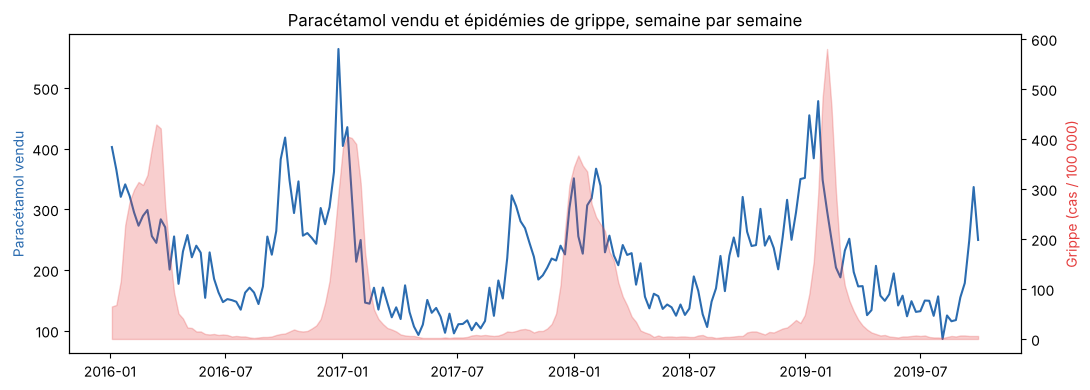

In [15]:
if os.path.exists(fichier_grippe):
    dates = pd.to_datetime(tableau.index.astype(str) + "1", format="%G%V%u")
    fig, ax1 = plt.subplots(figsize=(11, 4))
    ax1.plot(dates, tableau["N02BE"], color="#2b6cb0")
    ax1.set_ylabel("Paracétamol vendu", color="#2b6cb0")
    ax2 = ax1.twinx()
    ax2.fill_between(dates, tableau["grippe"], color="#e53e3e", alpha=0.25)
    ax2.set_ylabel("Grippe (cas / 100 000)", color="#e53e3e")
    ax1.set_title("Paracétamol vendu et épidémies de grippe, semaine par semaine")
    plt.tight_layout()
    plt.show()

En semaine de forte grippe : **+51 % de paracétamol, +40 % d'asthme, +30 % d'ibuprofène**.
Mais les ventes montent **dès septembre-octobre, avant la grippe** : la saison (rentrée, rhumes, froid) explique une grande partie de la hausse, et la grippe ajoute un pic par-dessus.

## Conclusions

1. Données fiables, sauf l'export **mensuel**, écarté.
2. Paracétamol, asthme et antihistaminiques sont **fortement saisonniers** : adapter les stocks au calendrier.
3. La prévision du mois suivant **bat la méthode naïve pour 5 groupes sur 8**.
4. **Renforcer le stock dès septembre**, puis suivre le bulletin hebdomadaire de sentiweb.fr pour augmenter les commandes quand l'épidémie démarre.